In [1]:
#General tools
import numpy as np
import pandas as pd
import seaborn as sns
import os


#Heatmap tools
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap, to_rgb
import matplotlib.patches as mpatches


In [4]:
#Create your interaction type figure
#Remember that it is important: Where is my storage dir? Where is my result dir? How many folders do I have?

ligand_res = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_interactions/stabilizers/'
res_path = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_interactions/stabilizers/pose_1/processed/'


In [5]:
#Ligand preparation:
#The csv file generated with 04 contains a lot of information that could be useful but not in this especific context
#Therefore, we need to clean the data to a more numeric foramt to continue to use it
#We will extract only the data of the present features types and the position where it happends

#To do so, we will follow the next steps: 
#1. Read your file
#2. Add a column to your csv table called presence, everytime that an interaction is found, a 1 will be added
#3. Reshape your table with pivot: index='feature',columns='prot_res_num', values='presence', fill_value=0  
#Now we have a table with the interaction type, the position, and the 1 for presence, but we do not have all 0-452 positions of the protein
#4. We will reshape our table again to have 452 columns and our interaction types as rows
#If a previous position had already an interaction(a 1) it will be matched with the new columns and the information will be conserved
#If the column is new,, with the fill value= 0 we will add new 0 to our empty data
#5. At the end we will have a csv file with the 452 positions, the interaction types, and 1/0 respectively



#Define iteration through folders

pos_number= '1'

for folder in os.listdir(ligand_res):
    sub_folder= os.path.join(ligand_res, folder)  
    
    #Define iteration through files
    
    for file in os.listdir(sub_folder):               
        file_path = os.path.join(sub_folder, file)
            
        if file.split('.') [-1] != 'csv':
            continue
            
        if file.split('_') [6] == pos_number:

            print(file) #Checkpoint: what files am i opening?
                
            
            #Read your filtered files    
            ligands = pd.read_csv(file_path)

            #We need a new DataFrame: rows = features type, cols =  0–452, filled with 0, then we fill up with 1

            # Add a column of 1s for presence
            ligands['presence'] = 1

            # Pivot table: rows = features, columns = residues, values = presence
            df_prot_res = ligands.pivot_table(
            index='feature',          # feature names as rows
            columns='prot_res_num',   # residue numbers as columns
            values='presence',        # use the presence column
            fill_value=0              # fill missing values with 0
            )

            # Make sure all residues 0–452 are present as columns
            df_prot_res = df_prot_res.reindex(columns=range(453), fill_value=0)

            #print(df_prot_res)
            csv_file_name = file.split('.')[0] + '.csv'
            docking_dir = os.path.join(res_path, csv_file_name)
            df_prot_res.to_csv(docking_dir)
            


           


dock_smina_PAH_6N1K_40_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_15_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_7_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_9_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_59_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_14_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_3_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_11_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_12_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_39_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_10_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_8_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_35_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_61_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_58_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_56_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_6_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_5_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_55_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_34_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_62_pose_1_stabilizer.csv
dock_smina_PAH_6N1K_37_pose_1_stabilizer.csv
dock_smina_PAH_6

In [6]:
#Prepare the data for your colormap

#Define your dir
ligand_path = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_interactions/stabilizers/pose_1/processed/'

#1. Define a dictionary with the interaction type and the desired color that represents it
#Now we need to transform our csv data into a np array for a better depiction

#2. Create a data set to save your data: all_colored_data = []

#3. Crerate a numpy array fille dup with 0s
#My ligands csv file has also a shape: ligans.shape(rows, columns), a 2D shape
#ligands.shape[0]= rows, ligands.shape[1]= columns
#(ligands.shape[0], ligands.shape[1], 3) ~ (_,_,3) MEAN THAT YOU ARE ADDING A NEW DIMENSION, now your data has an new dimension with 3 values on it
#But why? Because you need to add color code!
#With the np.zeros() you create an array with any shape and you fill it with 0 and, in this case, with the data con the table

#4. Add your color code
#4.1. Define your for loop
#for i, feat in enumerate(ligands.index):         #i is numeric index row, feat is the row label
#rgb = np.array(to_rgb(row_color_map[feat]))      #the to_rgb is a predefined function that your import at the beginning of the code

#This line selected the dictionary that you defined, specifically the features, so the colors and turns it into an array
#The to_rgb will generate the color code for each feature
#row color: converts your color name into a color code for the rbg code ("lightblue" → (0.678, 0.847, 0.902))

#4.2 Now we need a code that loops though the columns: for j in range(ligands.shape[1]):

#ligands.iloc[i, j]: .iloc allows integer-based indexing in pandas DataFrames
#if ligands.iloc[i, j] == 1:  basically means check if the current position/cell defined by row and colum is equal to 1
#If is 1 then do the following

#4.3 colored data defined your previously defined array and adds the values to this third dimension that we just defined
#We will fill it up with the rgb function that we defined before! for the colors we selected!

#color as string -> color as rgb code 
        
#5. Define white as other value:
#colored_data[i, j, :] = [1, 1, 1], so if there is no defined value, you can define it as white

#6. Stack your data into a np vertical array
      
      
row_color_map = { 
    'hydrophobic': 'gold',
    
    'pistack': 'yellowgreen',
    'pication_ligand_ring': 'limegreen',
    'pication_ligand_charge': 'forestgreen',
    
    'halogen_ligand_donnor': 'mediumpurple',
    
    'hbond_ligand_acceptor': 'dodgerblue',
    'hbond_ligand_donnor': 'blue',
    
    'waterbridge':'red',
    
    'saltbridge': 'hotpink',
    'ionic_ligand_positive': 'hotpink',
    'ionic_ligand_negative': 'orange',
    
    'metal': 'slategray'
}


all_colored_data = []

#Open your processed csv files in a ordered way, this will make the difference when adding the data to your heatmap.
#You need to do this in this step if you want to have the right order in your figure

for file in sorted(os.listdir(ligand_path)):            
    file_path = os.path.join(ligand_path, file)
    
    if file.split('.')[1] != 'csv': 
        continue
    
    #Read your CSV file
    ligands = pd.read_csv(file_path, index_col=0)  

    
    
    colored_data = np.zeros((ligands.shape[0], ligands.shape[1], 3))
    
    
    for i, feat in enumerate(ligands.index):                  
        rgb = np.array(to_rgb(row_color_map[feat]))           
        for j in range(ligands.shape[1]):
            if ligands.iloc[i, j] == 1:                      
                colored_data[i, j, :] = rgb                  
            else:
                colored_data[i, j, :] = [1, 1, 1]             
            

    #Save your data to your list
    all_colored_data.append(colored_data)  

#Convert your data: stacks arrays vertically    
final_colored_data = np.vstack(all_colored_data)



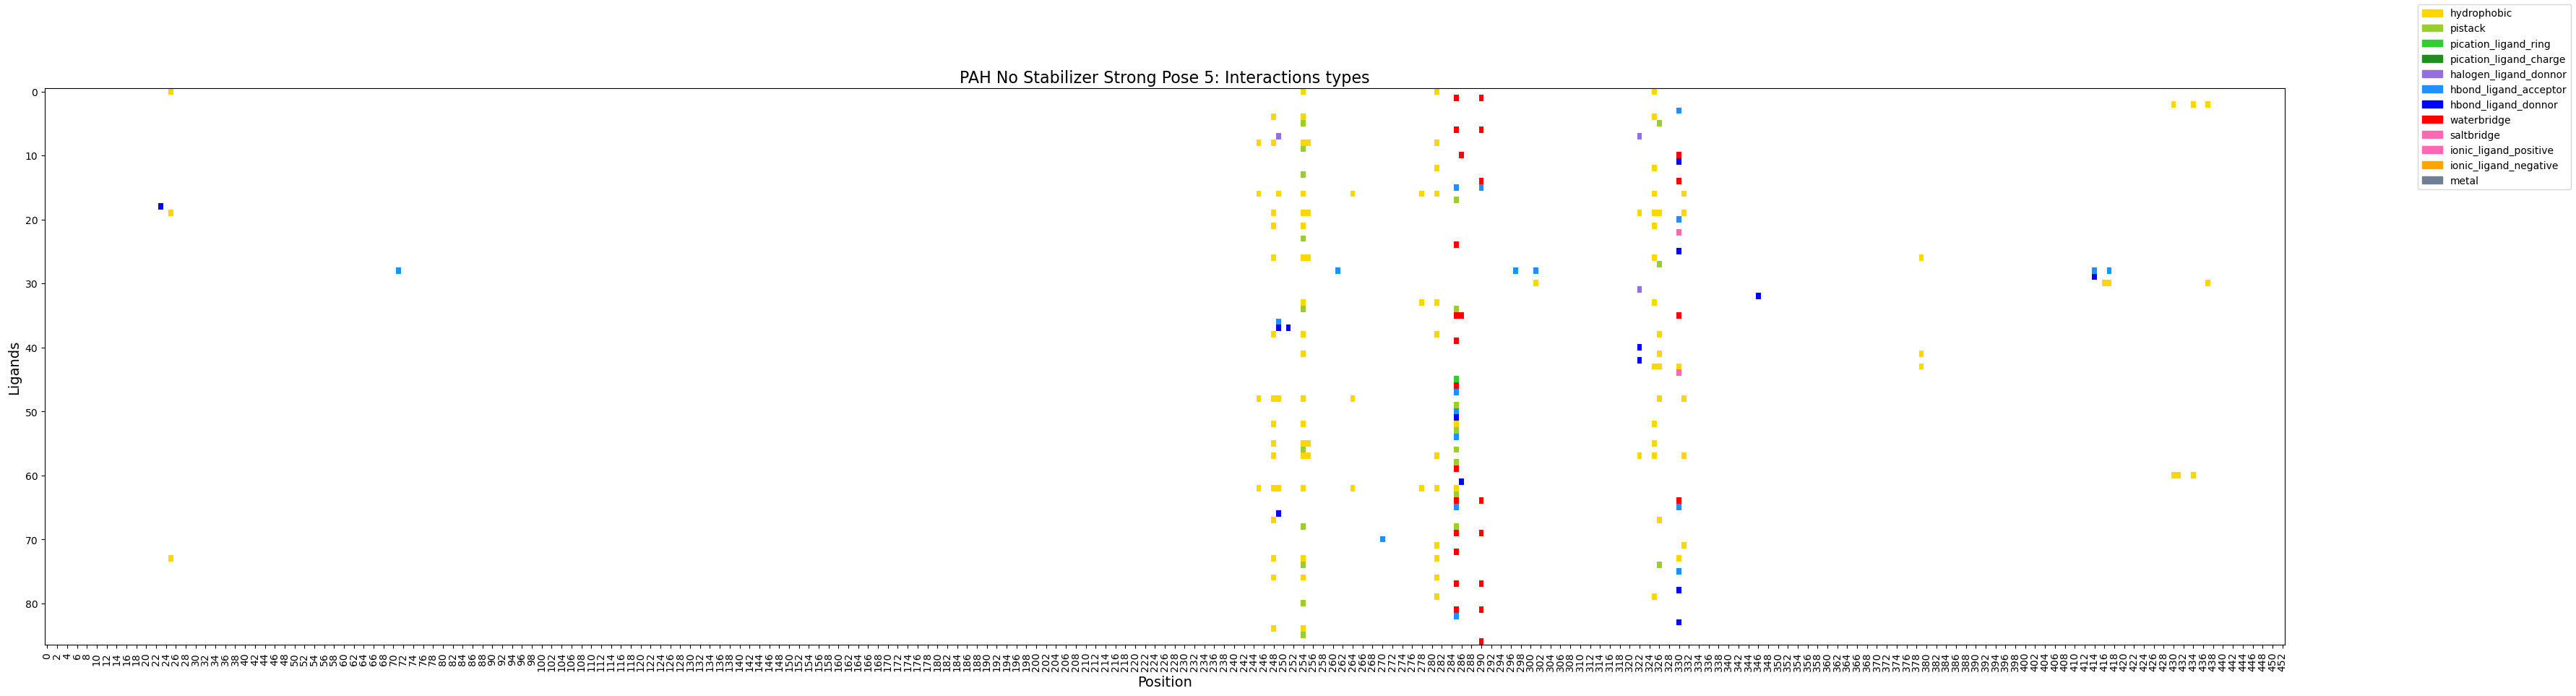

In [7]:
#Make your heatmap

#Define your legend patches
# Make patches (cuadrados) for each dictionary entry
patches = [mpatches.Patch(color=color, label=key) for key, color in row_color_map.items()]


# Plotting
fig, ax = plt.subplots(1, 1, figsize=(40, 10), 
                       gridspec_kw={'height_ratios': [1]})

# Define x-tick positions (every 2 from 0 to 452)
xticks = np.arange(0, 453, 2)
#yticks = np.arange(0, 65, 2)

ax.imshow(final_colored_data, aspect='auto')
ax.set_title('PAH No Stabilizer Strong Pose 5: Interactions types', fontsize=16)
ax.set_xlabel('Position', fontsize=14)
ax.set_ylabel('Ligands', fontsize=14)
ax.tick_params(axis='x', rotation=90)
ax.set_xticks(xticks)
ax.set_xticklabels(xticks)

fig.legend(handles=patches, loc='outside right upper')


#plt.savefig('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_figures/no_stabilizers/strong_binding/no_stabilizer_strong_interaction_pose_5')

plt.show()
